In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
root_dir = Path().resolve().parent if "demo_notebooks" in str(Path().resolve()) else Path().resolve()
src_path = root_dir / "src"

if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

In [3]:
from eo_toolkit import (
    load_cached_sentinel2_as_numpy_tensor,
    compute_residuals_and_baseline,
    compute_ndre_from_patch,
)

In [4]:
justin = "sentinel2_lat_44.7401_lon_5.3502019_size_2000"
darney = "sentinel2_lat_48.008_lon_6.0816_size_3000"

path_to_data = Path("../assets/data") / darney
sentinel2_data = load_cached_sentinel2_as_numpy_tensor(path_to_data)

In [5]:
bands = sentinel2_data["bands"]            # Shape: (N, C, H, W)
dates = sentinel2_data["dates"]            # Shape: (N,)
clouds = sentinel2_data["cloud_cover"]     # Shape: (N,)
band_names = sentinel2_data["band_names"]  # List of saved band names

In [6]:
# Extract spatial median for NDRE dynamically across each patch
ndre_medians = []
for i in range(len(dates)):
    patch_data = bands[i]  # Shape: (C, H, W)
    try:
        ndre_map = compute_ndre_from_patch(patch_data, band_names, nir_band="nir08", re_band="rededge1")
        valid_pixels = ndre_map[np.isfinite(ndre_map)]
        ndre_medians.append(np.nanmedian(valid_pixels) if len(valid_pixels) > 0 else np.nan)
    except ValueError as e:
        print(f"Skipping date {dates[i]}: {e}")
        ndre_medians.append(np.nan)

In [7]:
# Build Pandas series with DatetimeIndex
s = pd.Series(ndre_medians, index=pd.to_datetime(dates)).sort_index()

# Aggregates all intra-month observations into monthly medians
s = s.resample("MS").median()

residuals, baseline = compute_residuals_and_baseline(s)

In [8]:
def plot_s2_analysis(s: pd.Series, baseline: pd.Series, residuals: pd.Series, std_res: float) -> None:
    """Plots raw NDRE evolution, baseline, and residual anomaly time series."""
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

    # Raw vs Baseline
    ax1.plot(s.index, s, marker="o", color="#2ca02c", label="Spatial Median NDRE", linewidth=1.5)
    ax1.plot(baseline.index, baseline, linestyle="--", color="#7f7f7f", label="Baseline (de-seasoned & de-trended)", alpha=0.8)
    ax1.set_ylabel("NDRE [-]", fontsize=11)
    ax1.set_title("Sentinel-2 NDRE & residual analysis", fontsize=13, fontweight="bold")
    ax1.grid(True, linestyle=":", alpha=0.6)
    ax1.legend(loc="upper left")

    # Residual anomalies
    res_colors = np.where(residuals < 0, "#d62728", "#1f77b4")
    ax2.bar(residuals.index, residuals, width=20, color=res_colors, alpha=0.75, label="NDRE residual")
    ax2.axhline(0, color="black", linewidth=0.8, linestyle="-")
    ax2.axhline(-2 * std_res, color="#d62728", linestyle="--", linewidth=1.2, label=r"$-2\sigma$")
    ax2.axhline(2 * std_res, color="#1f77b4", linestyle="--", linewidth=1.2, label=r"$+2\sigma$")

    ax2.set_ylabel(r"NDRE residual ($\Delta\text{NDRE}$)", fontsize=11)
    ax2.set_xlabel("Date", fontsize=11)
    ax2.grid(True, linestyle=":", alpha=0.6)
    ax2.legend(loc="lower left")

    plt.tight_layout()
    plt.show()

### Detect anomalies

In [9]:
std_residual = residuals.std()

# Capture both lower (-threshold_factor*sigma) and upper (+threshold_factor*sigma) bounds
threshold_factor = 2.0

anomalies = residuals[(residuals < -threshold_factor * std_residual) | (residuals > threshold_factor * std_residual)]

print("Detected anomalies:")
if not anomalies.empty:
    for dt, val in anomalies.items():
        direction = "NEGATIVE (Stress)" if val < 0 else "POSITIVE (Growth)"        
        raw_val = s.loc[dt] if dt in s.index and pd.notna(s.loc[dt]) else float('nan')
        print(f"Date: {dt.strftime('%Y-%m-%d')} | Type: {direction} | Residual: {val:+.4f} | Raw NDRE: {raw_val:.4f}")
else:
    print("No severe anomalies detected.")

Detected anomalies:
Date: 2018-04-01 | Type: POSITIVE (Growth) | Residual: +0.0870 | Raw NDRE: 0.4296
Date: 2021-05-01 | Type: NEGATIVE (Stress) | Residual: -0.1649 | Raw NDRE: 0.4761
Date: 2022-02-01 | Type: NEGATIVE (Stress) | Residual: -0.1329 | Raw NDRE: 0.2039
Date: 2025-12-01 | Type: NEGATIVE (Stress) | Residual: -0.2009 | Raw NDRE: 0.1975
Date: 2026-04-01 | Type: POSITIVE (Growth) | Residual: +0.1523 | Raw NDRE: 0.5092


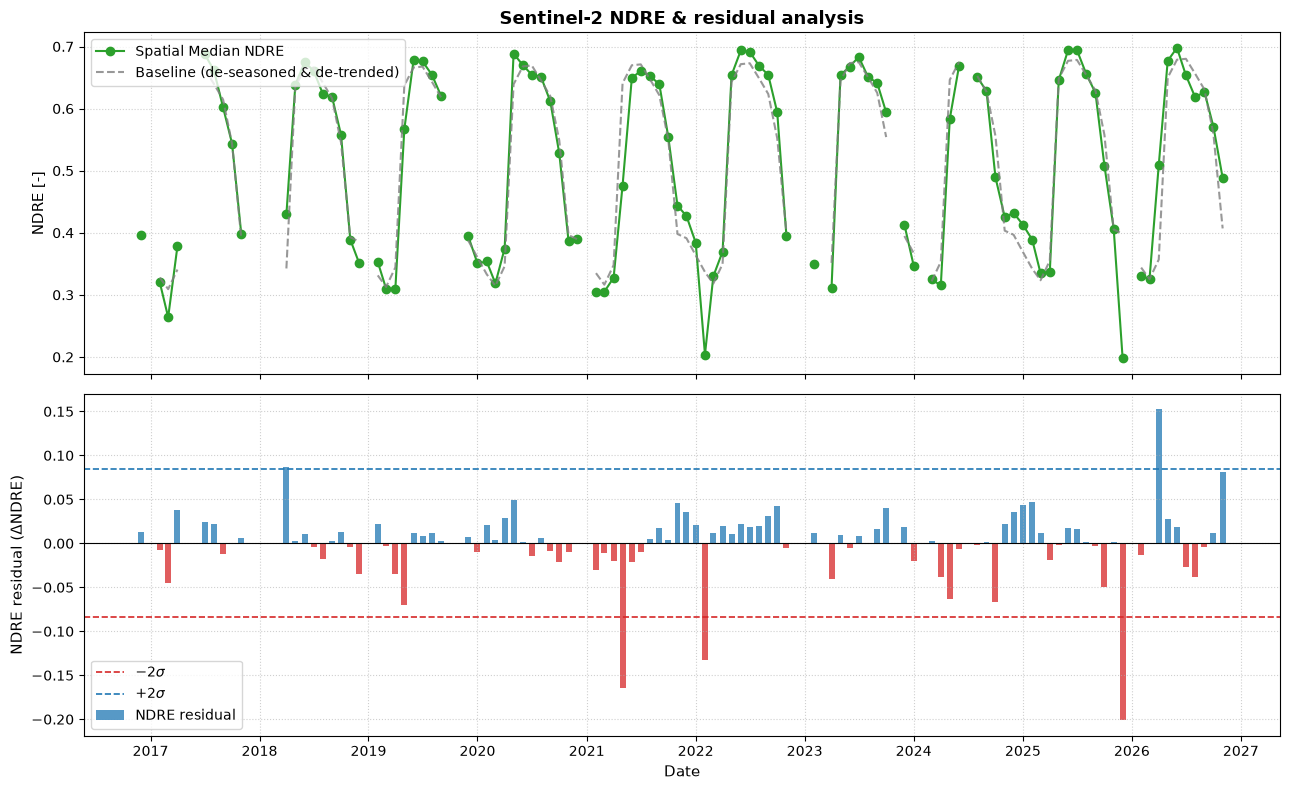

In [10]:
plot_s2_analysis(s, baseline, residuals, std_residual)